# ¿Mismo título, mismo ingreso?
## Ingresos laborales de mujeres y hombres con educación superior en Colombia (GEIH, enero–julio 2026)

**Visualización I · Proyecto 3 · Componente Python (Seaborn y Plotly)**
Equipo 3: Alejandro Pardo Costo y Juan Tomás Rincón Pinzón

### Instalación de dependencias

Se corre una sola vez. `nbformat` hace falta para que `fig.show()` de Plotly se vea dentro de VS Code.

In [1]:
%pip install -q pandas numpy matplotlib seaborn plotly nbformat

Note: you may need to restart the kernel to use updated packages.


## 1. Para quién es este análisis

| | |
|---|---|
| **Audiencia** | Mujeres de 18 a 28 años que están terminando o acaban de terminar un programa técnico, tecnológico o universitario y van a buscar su primer empleo. |
| **Qué necesitan entender** | Si con el mismo nivel educativo las mujeres reciben lo mismo que los hombres, y si esa diferencia cambia con la edad, el sector donde se trabaja y el departamento. Con eso pueden llegar mejor informadas a una entrevista o a una negociación salarial. |
| **Pregunta analítica** | ¿Qué diferencias de ingreso laboral se observan entre mujeres y hombres con educación superior en Colombia (enero–julio 2026) y cómo varían según la edad y el departamento? |

Este notebook es una de las tres piezas del proyecto. Cada herramienta responde una parte distinta de la pregunta para no repetir gráficos:

| Herramienta | Qué aporta a la historia |
|---|---|
| Power BI | Panorama general: ingreso promedio por nivel educativo y sexo, evolución mensual, cotización a pensión y detalle por ciudad. |
| **Python, Seaborn (este notebook)** | (1) Cómo se reparten los ingresos por hora, no solo el promedio. (2) Cómo cambia la brecha según la edad. |
| **Python, Plotly (este notebook)** | Exploración por sector económico y grupo de edad. |
| R | Mapa de la brecha por departamento. Este notebook prepara la tabla que usa el mapa. |

Las definiciones están en `docs/Definiciones_compartidas.md` y son las mismas en las tres herramientas.

## 2. Datos y preparación

**Fuente.** Gran Encuesta Integrada de Hogares (GEIH) 2026 del DANE, marco 2018, meses de enero a julio. Usamos las mismas tablas del Proyecto 1:

- *Características generales, seguridad social en salud y educación*: sexo, edad, nivel educativo y departamento de cada persona.
- *Ocupados*: ingreso laboral, horas trabajadas, rama de actividad y factor de expansión.

Los 14 archivos CSV (2 tablas × 7 meses) vienen dentro de `datos/originales/geih_2026/Tablas_Seleccionadas_GEIH_2026.zip`. El zip no se modifica: el notebook lo lee directamente y toda la preparación ocurre en memoria.

In [2]:
from pathlib import Path
import io
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.graph_objects as go

# El notebook vive en python/, pero también se puede abrir desde la raíz del repo o desde Colab.
ZIP_RELATIVO = Path("datos/originales/geih_2026/Tablas_Seleccionadas_GEIH_2026.zip")
URL_ZIP = ("https://github.com/AlejandroP212/proyecto3-narrativa-visual/raw/main/"
           "datos/originales/geih_2026/Tablas_Seleccionadas_GEIH_2026.zip")

BASE = next((c for c in [Path("."), Path("..")] if (c / ZIP_RELATIVO).exists()), None)
if BASE is None:
    # En Colab no está el repo clonado: descargamos el mismo zip desde GitHub
    BASE = Path(".")
    (BASE / ZIP_RELATIVO).parent.mkdir(parents=True, exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_ZIP, BASE / ZIP_RELATIVO)
    except Exception as error:
        raise FileNotFoundError(
            "No se encontró el zip de la GEIH ni se pudo descargar. "
            "Abre el notebook desde la carpeta python/ del repositorio."
        ) from error

RUTA_ZIP = BASE / ZIP_RELATIVO
CARPETA_PROCESADOS = BASE / "datos" / "procesados"
CARPETA_HTML = BASE / "python" / "html"
CARPETA_IMG = BASE / "presentacion" / "img"
for carpeta in (CARPETA_PROCESADOS, CARPETA_HTML, CARPETA_IMG):
    carpeta.mkdir(parents=True, exist_ok=True)

print("Datos:", RUTA_ZIP.resolve())

Datos: /home/ana/code/Semestre_5/Visualizacion_1/Proyecto_3/datos/originales/geih_2026/Tablas_Seleccionadas_GEIH_2026.zip


### Ingredientes del análisis

En esta celda dejamos fijos los colores, las categorías y los formatos que se usan en todos los gráficos. Los colores son los mismos del Power BI y del mapa en R: azul para hombres y ocre para mujeres. La pareja azul/morado del Proyecto 1 no se distinguía bien con daltonismo, por eso la cambiamos.

In [3]:
COLORES = {"Hombre": "#1F4E79", "Mujer": "#B8862B"}
ACENTO = "#AD4A3C"      # se usa para resaltar la brecha
NEUTRO = "#6B7280"      # textos secundarios y barras sin resaltar
GRIS_CLARO = "#D1D5DB"
ORDEN_SEXO = ["Hombre", "Mujer"]

# P3042 = nivel educativo más alto alcanzado. Educación superior = códigos 8 a 13.
NIVEL_SUPERIOR = {
    8: "Técnica o tecnológica", 9: "Técnica o tecnológica",
    10: "Universitaria",
    11: "Posgrado", 12: "Posgrado", 13: "Posgrado",
}
ORDEN_NIVEL = ["Técnica o tecnológica", "Universitaria", "Posgrado"]

# Grupos de edad (P6040). 18–28 es el rango de juventud de la Ley 1622 de 2013.
CORTES_EDAD = [17, 28, 40, 59, 120]
ORDEN_EDAD = ["18–28", "29–40", "41–59", "60 y más"]

# Secciones de la CIIU Rev. 4 A.C. a partir de la división de dos dígitos (RAMA2D_R4)
SECCIONES_CIIU = [
    (1, 3, "Agro y pesca"), (5, 9, "Minería"), (10, 33, "Industria manufacturera"),
    (35, 39, "Electricidad, gas y agua"), (41, 43, "Construcción"),
    (45, 47, "Comercio y reparación de vehículos"), (49, 53, "Transporte y almacenamiento"),
    (55, 56, "Alojamiento y servicios de comida"), (58, 63, "Información y comunicaciones"),
    (64, 66, "Finanzas y seguros"), (68, 68, "Actividades inmobiliarias"),
    (69, 75, "Actividades profesionales y científicas"),
    (77, 82, "Servicios administrativos y de apoyo"),
    (84, 84, "Administración pública y defensa"), (85, 85, "Educación"),
    (86, 88, "Salud y asistencia social"), (90, 93, "Arte y entretenimiento"),
    (94, 96, "Otros servicios"), (97, 98, "Hogares como empleadores"),
    (99, 99, "Organizaciones extraterritoriales"),
]

FUENTE = "Fuente: DANE, GEIH enero–julio 2026. Cálculos del Equipo 3."
SEMANAS_POR_MES = 4.3333   # el mismo factor que usa Power BI


def miles(valor):
    # 1234567 -> '1.234.567'
    return f"{valor:,.0f}".replace(",", ".")


def pct(valor, decimales=1):
    # 13.67 -> '13,7 %'
    return f"{valor:.{decimales}f}".replace(".", ",") + " %"


sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})

### Carga

Los CSV del DANE vienen separados por `;` y con codificación latin-1. Solo leemos las columnas que usa el análisis:

| Tabla | Columnas | Para qué |
|---|---|---|
| Ambas | `DIRECTORIO`, `SECUENCIA_P`, `HOGAR`, `ORDEN`, `PERIODO` | Llave para unir las dos tablas |
| Características | `P3271` sexo, `P6040` edad, `P3042` nivel educativo, `DPTO` departamento, `MES` | Variables de comparación |
| Ocupados | `INGLABO` ingreso laboral mensual, `P6800` horas por semana, `RAMA2D_R4` rama, `FEX_C18` factor de expansión | Ingresos y ponderación |

El archivo de abril se llama distinto ("Capítulos de características…"), así que buscamos las tablas por una parte del nombre y no por el nombre exacto.

In [4]:
LLAVE = ["DIRECTORIO", "SECUENCIA_P", "HOGAR", "ORDEN", "PERIODO"]
COLS_PERSONAS = LLAVE + ["MES", "DPTO", "P3271", "P6040", "P3042"]
COLS_OCUPADOS = LLAVE + ["INGLABO", "P6800", "RAMA2D_R4", "FEX_C18"]

personas, ocupados = [], []
with zipfile.ZipFile(RUTA_ZIP) as z:
    for nombre in sorted(z.namelist()):
        if not nombre.upper().endswith(".CSV"):
            continue
        opciones = dict(sep=";", dtype=str, encoding="latin-1")
        if "generales" in nombre:
            personas.append(pd.read_csv(z.open(nombre), usecols=COLS_PERSONAS, **opciones))
        elif "Ocupados" in nombre:
            ocupados.append(pd.read_csv(z.open(nombre), usecols=COLS_OCUPADOS, **opciones))

personas = pd.concat(personas, ignore_index=True)
ocupados = pd.concat(ocupados, ignore_index=True)

print(f"Personas encuestadas: {miles(len(personas))}  |  Ocupados: {miles(len(ocupados))}")
personas.groupby("MES").size().rename("personas").to_frame().join(
    ocupados.assign(MES=ocupados["PERIODO"].str[4:6]).groupby("MES").size().rename("ocupados")
)

Personas encuestadas: 468.434  |  Ocupados: 206.712


,personas,ocupados
MES,,
01,66606,28359
02,67736,29892
03,66909,29691
04,67349,29874
05,67065,29920
06,66285,29459
07,66484,29517


### Unión de las tablas

Cada ocupado debe tener exactamente una fila en la tabla de características. Por eso se une con la llave completa e incluye `HOGAR`: sin ella se duplican personas que comparten vivienda, un error que ya habíamos encontrado en el Proyecto 1. Con `validate="1:1"`, pandas detiene la ejecución si aparece algún duplicado.

In [5]:
base = ocupados.merge(personas, on=LLAVE, how="left", validate="1:1", indicator=True)
sin_pareja = (base["_merge"] != "both").sum()
print(f"Ocupados sin pareja en características: {sin_pareja}")
base = base.drop(columns="_merge")

Ocupados sin pareja en características: 0


### Variables y filtros

Pasos de la preparación:

1. Las columnas numéricas llegan como texto y se convierten. `FEX_C18` usa punto decimal, así que se lee sin ajustes. En Power Query fue necesario cambiar la configuración regional.
2. **Ingreso por hora** = ingreso mensual ÷ (horas por semana × 4,3333).
3. Se conservan solo los ocupados con ingreso laboral mayor que 0, horas mayores que 0 y educación superior (P3042 entre 8 y 13).

La tabla de abajo muestra cuántos registros sale en cada filtro, para que quede claro qué se excluye.

In [6]:
for col in ["INGLABO", "P6800", "P6040", "P3042", "RAMA2D_R4"]:
    base[col] = pd.to_numeric(base[col], errors="coerce")
base["FEX"] = pd.to_numeric(base["FEX_C18"])
base["sexo"] = base["P3271"].map({"1": "Hombre", "2": "Mujer"})
base["HORAS_MES"] = base["P6800"] * SEMANAS_POR_MES

pasos = [("Ocupados enero–julio", len(base))]
datos = base[base["INGLABO"] > 0]
pasos.append(("Con ingreso laboral mayor que 0", len(datos)))
datos = datos[datos["P6800"] > 0]
pasos.append(("Con horas trabajadas mayores que 0", len(datos)))
datos = datos[datos["P3042"].between(8, 13)].copy()
pasos.append(("Con educación superior (P3042 = 8 a 13)", len(datos)))

datos["nivel"] = pd.Categorical(datos["P3042"].map(NIVEL_SUPERIOR), ORDEN_NIVEL, ordered=True)
datos["grupo_edad"] = pd.cut(datos["P6040"], CORTES_EDAD, labels=ORDEN_EDAD)
datos["ingreso_hora"] = datos["INGLABO"] / datos["HORAS_MES"]


def seccion_ciiu(division):
    for desde, hasta, nombre in SECCIONES_CIIU:
        if desde <= division <= hasta:
            return nombre
    return None


datos["sector"] = datos["RAMA2D_R4"].map(seccion_ciiu)

pd.DataFrame(pasos, columns=["Paso", "Registros"]).assign(
    Registros=lambda t: t["Registros"].map(miles))

,Paso,Registros
0,Ocupados enero–julio,206.712
1,Con ingreso laboral mayor que 0,201.277
2,Con horas trabajadas mayores que 0,201.277
3,Con educación superior (P3042 = 8 a 13),76.488


In [7]:
# Revisión rápida de faltantes y rangos en la tabla final
print("Faltantes por columna:")
print(datos[["sexo", "P6040", "grupo_edad", "nivel", "sector", "DPTO", "FEX"]].isna().sum().to_string())
print(f"\nMenores de 18 con educación superior (quedan fuera de los grupos de edad): "
      f"{datos['grupo_edad'].isna().sum()}")
print(f"Viviendas distintas: {miles(datos['DIRECTORIO'].nunique())}")
print(f"Departamentos: {datos['DPTO'].nunique()}")

Faltantes por columna:
sexo           0
P6040          0
grupo_edad    86
nivel          0
sector         0
DPTO           0
FEX            0

Menores de 18 con educación superior (quedan fuera de los grupos de edad): 86
Viviendas distintas: 58.995
Departamentos: 33


**Lectura.** De 206.712 ocupados quedan 76.488 personas con educación superior, ingreso y horas reportadas. Ninguna columna clave tiene faltantes. Las personas que no reportan ingreso o que reportan 0 se excluyen porque no se puede saber cuánto ganan, y se dice explícitamente en las limitaciones.

### Cómo se calculan las cifras

Todas las cifras están **ponderadas por el factor de expansión** (`FEX_C18`). Cada persona encuestada representa a muchas otras: una persona con FEX = 200 "cuenta" por 200.

- **Ingreso mensual promedio** = Σ(ingreso × FEX) / Σ(FEX).
- **Ingreso por hora** = Σ(ingreso × FEX) / Σ(horas del mes × FEX). Es el ingreso total dividido por las horas totales del grupo y se lee como "por cada hora trabajada". Es la misma fórmula de la medida `Ingreso_Hora_Promedio` de Power BI.
- **Brecha (%)** = (hombres − mujeres) / hombres × 100. Si es positiva, las mujeres reciben menos.

**Margen de error (bootstrap).** La GEIH es una muestra, así que cada cifra tiene incertidumbre. Para medirla repetimos el cálculo 500 veces. En cada repetición, a cada vivienda se le asigna un peso aleatorio (Poisson con media 1), como si se volviera a sacar la muestra. El rango donde cae el 95 % de los resultados es el intervalo de confianza. Se remuestrea por vivienda (`DIRECTORIO`) y no por persona, porque quienes viven juntos se parecen entre sí. Es una aproximación: el DANE usa el diseño muestral completo, con estratos y conglomerados, y esos datos no vienen en las tablas públicas.

In [8]:
def ingreso_mensual(tabla):
    return np.average(tabla["INGLABO"], weights=tabla["FEX"])


def ingreso_por_hora(tabla):
    return (tabla["INGLABO"] * tabla["FEX"]).sum() / (tabla["HORAS_MES"] * tabla["FEX"]).sum()


def brecha(tabla, medida=ingreso_por_hora):
    hombres = medida(tabla[tabla["sexo"] == "Hombre"])
    mujeres = medida(tabla[tabla["sexo"] == "Mujer"])
    return (hombres - mujeres) / hombres * 100


def brecha_con_intervalo(tabla, repeticiones=500, semilla=2026):
    # Totales por vivienda y sexo: así cada repetición es una multiplicación de matrices
    sumas = (tabla.assign(I=tabla["INGLABO"] * tabla["FEX"], H=tabla["HORAS_MES"] * tabla["FEX"])
                  .groupby(["DIRECTORIO", "sexo"])[["I", "H"]].sum()
                  .unstack(fill_value=0))
    ingreso = sumas["I"][ORDEN_SEXO].to_numpy()   # columnas: Hombre, Mujer
    horas = sumas["H"][ORDEN_SEXO].to_numpy()

    pesos = np.random.default_rng(semilla).poisson(1, size=(repeticiones, len(sumas)))
    por_hora = (pesos @ ingreso) / (pesos @ horas)  # ingreso por hora en cada repetición
    brechas = (1 - por_hora[:, 1] / por_hora[:, 0]) * 100

    puntual = brecha(tabla)
    return {
        "brecha": puntual,
        "ic_inf": np.percentile(brechas, 2.5),
        "ic_sup": np.percentile(brechas, 97.5),
        "cv_hombres": por_hora[:, 0].std() / por_hora[:, 0].mean() * 100,
        "cv_mujeres": por_hora[:, 1].std() / por_hora[:, 1].mean() * 100,
    }


def mediana_ponderada(valores, pesos):
    orden = np.argsort(valores.to_numpy())
    v, w = valores.to_numpy()[orden], pesos.to_numpy()[orden]
    acumulado = np.cumsum(w)
    return v[np.searchsorted(acumulado, acumulado[-1] / 2)]

### Cifras de control

Estas son las cifras que deben dar igual en Power BI (consulta DAX de `LEEME_TOMAS.md`) y en este notebook.

In [9]:
total_sup = brecha_con_intervalo(datos)
control = pd.DataFrame({
    "Indicador": [
        "Ingreso mensual promedio, hombres", "Ingreso mensual promedio, mujeres",
        "Brecha de ingreso mensual", "Ingreso por hora, hombres", "Ingreso por hora, mujeres",
        "Brecha de ingreso por hora", "IC 95 % de la brecha por hora",
    ],
    "Valor": [
        "$ " + miles(ingreso_mensual(datos[datos.sexo == "Hombre"])),
        "$ " + miles(ingreso_mensual(datos[datos.sexo == "Mujer"])),
        pct(brecha(datos, ingreso_mensual)),
        "$ " + miles(ingreso_por_hora(datos[datos.sexo == "Hombre"])),
        "$ " + miles(ingreso_por_hora(datos[datos.sexo == "Mujer"])),
        pct(total_sup["brecha"]),
        f"{pct(total_sup['ic_inf'])} a {pct(total_sup['ic_sup'])}",
    ],
})
control

,Indicador,Valor
0,"Ingreso mensual promedio, hombres",$ 4.068.584
1,"Ingreso mensual promedio, mujeres",$ 3.317.843
2,Brecha de ingreso mensual,"18,5 %"
3,"Ingreso por hora, hombres",$ 21.491
4,"Ingreso por hora, mujeres",$ 18.553
5,Brecha de ingreso por hora,"13,7 %"
6,IC 95 % de la brecha por hora,"11,2 % a 16,3 %"


**Lectura.** Entre las personas ocupadas con educación superior, las mujeres reciben en promedio $ 3.317.843 al mes y los hombres $ 4.068.584: una brecha mensual del 18,5 %. Por hora la brecha baja a 13,7 % (intervalo de 11,2 % a 16,3 %). Que se reduzca indica que parte de la diferencia mensual coincide con que las mujeres trabajan menos horas remuneradas. Que no desaparezca indica que, incluso por cada hora trabajada, reciben menos. Para el resto del análisis usamos la brecha **por hora**, porque compara a quienes trabajan jornadas distintas en igualdad de condiciones.

### Por qué comparamos solo a personas con el mismo nivel educativo

Si se compara a todos los ocupados sin distinguir el nivel educativo, la brecha casi desaparece. Esta celda muestra por qué.

In [10]:
con_ingreso = base[(base["INGLABO"] > 0) & (base["P6800"] > 0)]
composicion = pd.DataFrame({
    "% con educación superior": [
        con_ingreso.loc[(con_ingreso.sexo == s) & con_ingreso.P3042.between(8, 13), "FEX"].sum()
        / con_ingreso.loc[con_ingreso.sexo == s, "FEX"].sum() * 100
        for s in ORDEN_SEXO
    ]
}, index=ORDEN_SEXO).round(1)

print(f"Brecha mensual, todos los ocupados (la tarjeta general de Power BI): "
      f"{pct(brecha(con_ingreso, ingreso_mensual))}")
print(f"Brecha por hora, todos los ocupados (todos los niveles): {pct(brecha(con_ingreso))}")
print(f"Brecha por hora, solo educación superior:               {pct(brecha(datos))}\n")
composicion

Brecha mensual, todos los ocupados (la tarjeta general de Power BI): 8,6 %
Brecha por hora, todos los ocupados (todos los niveles): -3,8 %
Brecha por hora, solo educación superior:               13,7 %



,% con educación superior
Hombre,29.7
Mujer,44.1


**Lectura.** Entre todos los ocupados, las mujeres ganan por hora un 3,8 % *más* que los hombres. La razón es la composición del grupo: el 44,1 % de las mujeres ocupadas tiene educación superior, frente al 29,7 % de los hombres, y la educación superior se asocia con ingresos más altos. Al comparar personas con el **mismo** nivel educativo aparece la brecha del 13,7 %. Por esto la historia se cuenta a igual nivel educativo. Esta celda también explica por qué la brecha general del Power BI (8,6 %, mensual) es mucho menor que la de cada nivel.

## 3. Visualizaciones estáticas (Seaborn)

| # | Gráfico | Qué debe entender la audiencia | Por qué no repite a Power BI |
|---|---|---|---|
| 1 | Distribución del ingreso por hora por sexo y nivel educativo | La diferencia no la produce un pequeño grupo de hombres con sueldos altos: toda la distribución de las mujeres está más abajo. | Power BI muestra promedios. Aquí se ve a todas las personas. |
| 2 | Brecha por hora según grupo de edad | Al empezar la vida laboral la brecha es menor, y es más alta en los grupos de más edad. | Power BI no tiene la edad. Es la dimensión central para esta audiencia. |

Los títulos son descriptivos. Lo que se observa va en el subtítulo y en la celda de lectura.

### Gráfico 1. Distribución del ingreso por hora

**Qué necesita ver la audiencia.** Un promedio puede esconder cosas: la brecha podría deberse a unos pocos hombres con salarios muy altos. Al mostrar la forma completa de la distribución se ve si la diferencia afecta a todo el grupo.

**Por qué curvas de densidad.** Cada curva muestra dónde se concentran los ingresos por hora de cada sexo. La línea vertical marca la mediana: la mitad gana menos que ese valor y la otra mitad más. Se separa por nivel educativo para comparar títulos equivalentes. Para que la curva sea representativa de la población se pondera con el factor de expansión (`weights="FEX"`). Para dibujar las curvas usamos a quienes ganan hasta $ 60 mil por hora, que son el 95,5 % de la población ponderada. Hay unos pocos valores extremos (el máximo supera los 12 millones de pesos por hora, seguramente alguien que reporta muy pocas horas) que vuelven plana la curva si se incluyen. Esos valores **sí** entran en las medianas y en todas las cifras del notebook, igual que en Power BI.

Población con ingreso por hora hasta $ 60 mil: 95,5 %


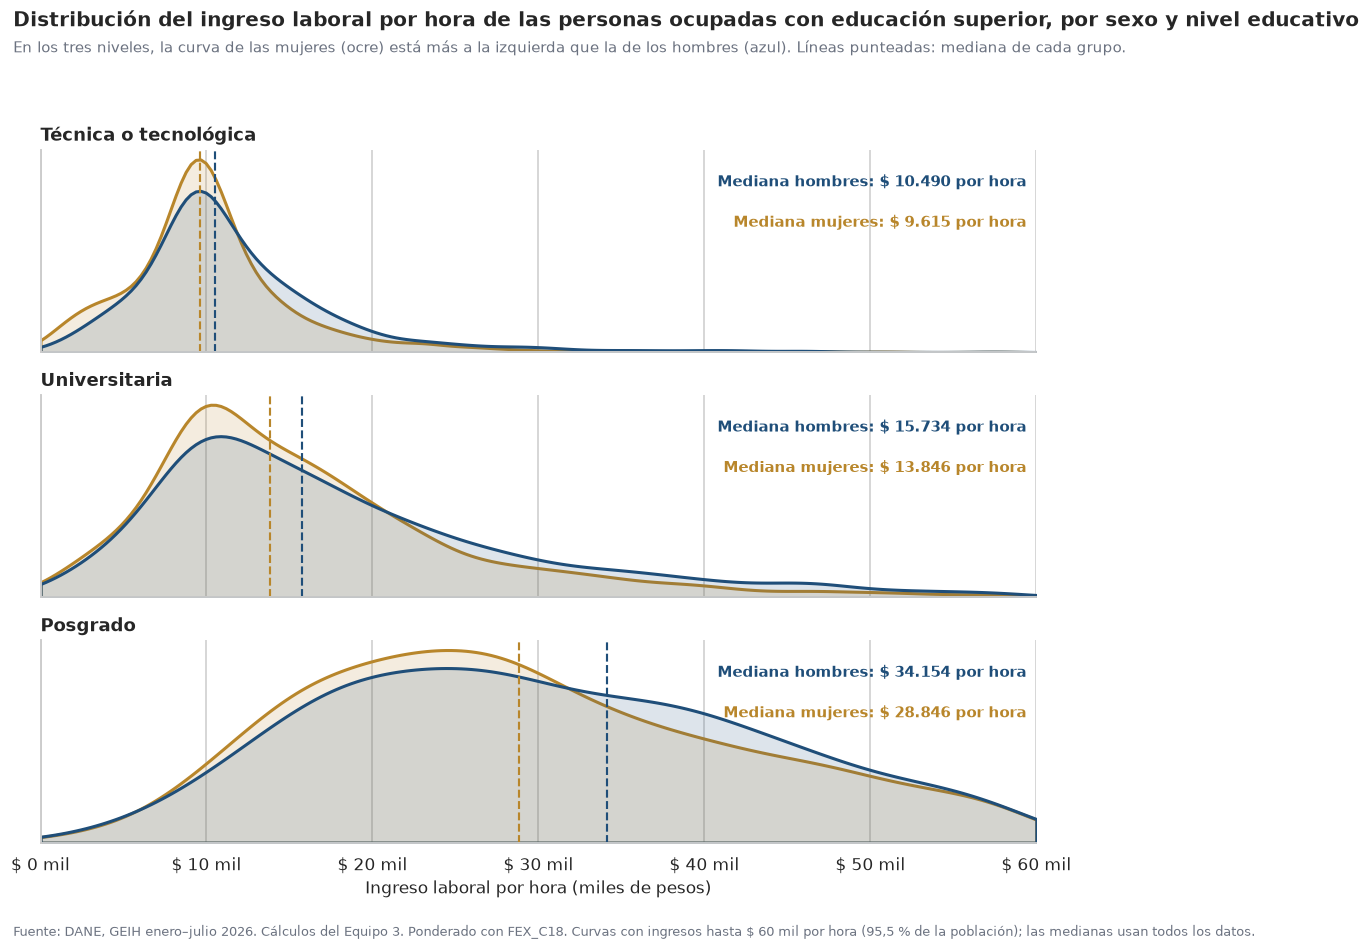

In [11]:
limite_x = 60   # miles de pesos por hora (percentil 95,5 ponderado)
datos["ingreso_hora_miles"] = datos["ingreso_hora"] / 1000
ETIQUETA_PLURAL = {"Hombre": "hombres", "Mujer": "mujeres"}
dentro = datos.loc[datos["ingreso_hora_miles"] <= limite_x, "FEX"].sum() / datos["FEX"].sum() * 100
print(f"Población con ingreso por hora hasta $ {limite_x} mil: {pct(dentro)}")

fig, ejes = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True)
medianas_g1 = {}

for ax, nivel in zip(ejes, ORDEN_NIVEL):
    subconjunto = datos[datos["nivel"] == nivel]
    sns.kdeplot(
        data=subconjunto[subconjunto["ingreso_hora_miles"] <= limite_x], x="ingreso_hora_miles", hue="sexo", hue_order=ORDEN_SEXO,
        weights="FEX", common_norm=False, fill=True, alpha=0.15, linewidth=2,
        palette=COLORES, clip=(0, limite_x), bw_adjust=1.2, legend=False, ax=ax,
    )
    for i, sexo in enumerate(ORDEN_SEXO):
        grupo = subconjunto[subconjunto["sexo"] == sexo]
        mediana = mediana_ponderada(grupo["ingreso_hora_miles"], grupo["FEX"])
        medianas_g1[(nivel, sexo)] = mediana * 1000
        ax.axvline(mediana, color=COLORES[sexo], linestyle="--", linewidth=1.4)
        ax.text(limite_x * 0.99, ax.get_ylim()[1] * (0.82 - 0.2 * i),
                f"Mediana {ETIQUETA_PLURAL[sexo]}: $ {miles(mediana * 1000)} por hora",
                color=COLORES[sexo], fontsize=10, fontweight="bold", ha="right")
    ax.set_title(nivel, loc="left", fontsize=11.5)
    ax.set_ylabel("")
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)

ejes[-1].set_xlim(0, limite_x)
ejes[-1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"$ {v:.0f} mil"))
ejes[-1].set_xlabel("Ingreso laboral por hora (miles de pesos)")

fig.suptitle("Distribución del ingreso laboral por hora de las personas ocupadas con "
             "educación superior, por sexo y nivel educativo",
             x=0.02, ha="left", fontsize=13, fontweight="bold")
fig.text(0.02, 0.935, "En los tres niveles, la curva de las mujeres (ocre) está más a la izquierda "
         "que la de los hombres (azul). Líneas punteadas: mediana de cada grupo.",
         fontsize=10, color=NEUTRO)
fig.text(0.02, -0.01, FUENTE + " Ponderado con FEX_C18. Curvas con ingresos hasta $ 60 mil por hora "
         "(95,5 % de la población); las medianas usan todos los datos.", fontsize=8.5, color=NEUTRO)
fig.tight_layout(rect=(0, 0.01, 1, 0.92))
fig.savefig(CARPETA_IMG / "python_g1_distribucion_ingreso_hora.png")
plt.show()

In [12]:
# Medianas que se citan en la lectura
pd.DataFrame(medianas_g1, index=["Mediana ingreso por hora"]).T.unstack().map(lambda v: "$ " + miles(v))

Mediana ingreso por hora          
                                        Hombre     Mujer
Posgrado                              $ 34.154  $ 28.846
Técnica o tecnológica                 $ 10.490   $ 9.615
Universitaria                         $ 15.734  $ 13.846

**Lectura.** En los tres niveles educativos la distribución de las mujeres está corrida hacia ingresos más bajos. La diferencia no se limita a los extremos: también se ve en la parte central, donde está la mayoría.

- **Técnica o tecnológica:** mediana de $ 9.615 por hora para las mujeres frente a $ 10.490 para los hombres.
- **Universitaria:** $ 13.846 frente a $ 15.734.
- **Posgrado:** $ 28.846 frente a $ 34.154.

En los programas técnicos las dos curvas tienen un pico estrecho y alto: la mitad central de las personas (del percentil 25 al 75) gana entre unos $ 8 mil y $ 13 mil por hora, y en ese tramo las dos curvas casi coinciden. En universitaria y posgrado las curvas son más anchas y la de los hombres tiene más peso en los ingresos altos.

Para la audiencia, el mensaje es que obtener un título más alto se asocia con ingresos más altos para las mujeres (la mediana pasa de unos $ 9.600 a unos $ 28.800 por hora), pero en ningún nivel la curva coincide con la de los hombres. El gráfico describe diferencias y no explica sus causas: no tiene en cuenta la carrera, el cargo ni la experiencia.

### Gráfico 2. Brecha por hora según grupo de edad

**Qué necesita ver la audiencia.** La audiencia está en el grupo de 18 a 28 años. Le sirve saber qué brecha hay al empezar y cómo es en los grupos de más edad, que es el mercado al que va a llegar con los años.

**Por qué barras con intervalo.** Hay una sola cifra por grupo, así que las barras son la forma más directa de comparar. La línea negra de cada barra es el intervalo de confianza del 95 % calculado con el bootstrap. Si es larga, la cifra es menos precisa: le pasa al grupo de 60 años y más, que tiene menos personas en la muestra. La barra del grupo de la audiencia va en color de acento y las demás en gris, para que el ojo la encuentre de inmediato. La línea punteada es la brecha de todas las edades juntas.

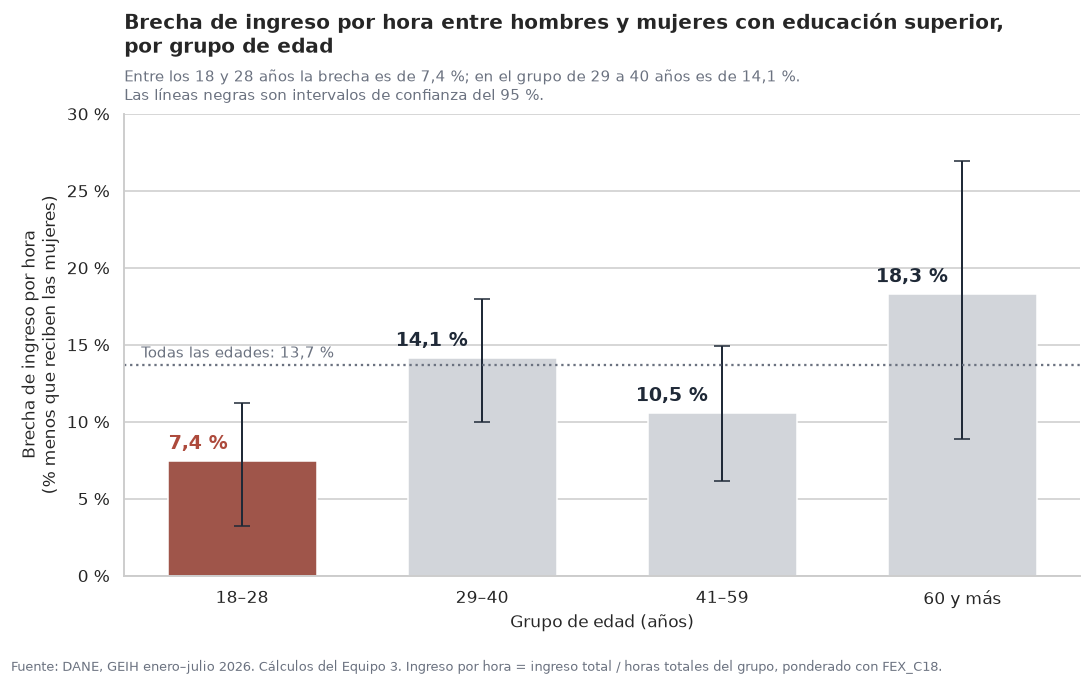

,grupo_edad,personas_muestra,brecha,intervalo
0,18–28,16714,"7,4 %","3,2 % a 11,2 %"
1,29–40,28717,"14,1 %","10,0 % a 17,9 %"
2,41–59,25849,"10,5 %","6,2 % a 14,9 %"
3,60 y más,5122,"18,3 %","8,9 % a 27,0 %"


In [13]:
filas = []
for grupo, tabla in datos.dropna(subset=["grupo_edad"]).groupby("grupo_edad", observed=True):
    resultado = brecha_con_intervalo(tabla)
    filas.append({"grupo_edad": grupo, "personas_muestra": len(tabla), **resultado})
brecha_edad = pd.DataFrame(filas)

colores_barras = [ACENTO if g == "18–28" else GRIS_CLARO for g in brecha_edad["grupo_edad"]]

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=brecha_edad, x="grupo_edad", y="brecha", order=ORDEN_EDAD,
            hue="grupo_edad", palette=dict(zip(brecha_edad["grupo_edad"], colores_barras)),
            legend=False, width=0.62, ax=ax)
ax.errorbar(x=range(len(brecha_edad)), y=brecha_edad["brecha"],
            yerr=[brecha_edad["brecha"] - brecha_edad["ic_inf"],
                  brecha_edad["ic_sup"] - brecha_edad["brecha"]],
            fmt="none", ecolor="#1F2937", elinewidth=1.3, capsize=5)

for i, fila in brecha_edad.iterrows():
    ax.text(i - 0.06, fila["brecha"] + 0.5, pct(fila["brecha"]), ha="right", va="bottom",
            fontsize=12.5, fontweight="bold", color=ACENTO if fila["grupo_edad"] == "18–28" else "#1F2937")

ax.axhline(total_sup["brecha"], color=NEUTRO, linestyle=":", linewidth=1.5)
ax.text(-0.42, total_sup["brecha"] + 0.5, f"Todas las edades: {pct(total_sup['brecha'])}",
        ha="left", fontsize=9.5, color=NEUTRO)

ax.set_ylim(0, 30)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.set_xlabel("Grupo de edad (años)")
ax.set_ylabel("Brecha de ingreso por hora\n(% menos que reciben las mujeres)")
jovenes_edad = brecha_edad.set_index("grupo_edad").loc["18–28", "brecha"]
adultos_edad = brecha_edad.set_index("grupo_edad").loc["29–40", "brecha"]
ax.set_title("Brecha de ingreso por hora entre hombres y mujeres con educación superior,\n"
             "por grupo de edad", loc="left", pad=40)
ax.text(0, 1.03, f"Entre los 18 y 28 años la brecha es de {pct(jovenes_edad)}; en el grupo de 29 a 40 "
        f"años es de {pct(adultos_edad)}.\nLas líneas negras son intervalos de confianza del 95 %.",
        transform=ax.transAxes, fontsize=9.8, color=NEUTRO)
fig.text(0.01, -0.03, FUENTE + " Ingreso por hora = ingreso total / horas totales del grupo, "
         "ponderado con FEX_C18.", fontsize=8.5, color=NEUTRO)
fig.tight_layout()
fig.savefig(CARPETA_IMG / "python_g2_brecha_por_edad.png")
plt.show()

brecha_edad.assign(
    brecha=lambda t: t["brecha"].map(pct),
    intervalo=lambda t: t["ic_inf"].map(pct) + " a " + t["ic_sup"].map(pct),
)[["grupo_edad", "personas_muestra", "brecha", "intervalo"]]

In [14]:
# ¿La diferencia entre 18–28 y 29–40 es mayor que el margen de error?
# Los dos grupos son personas distintas, así que el error de la diferencia se aproxima
# combinando los errores de cada grupo (ancho del intervalo / 3,92 = error estándar).
e = brecha_edad.set_index("grupo_edad")
error = lambda g: (e.loc[g, "ic_sup"] - e.loc[g, "ic_inf"]) / 3.92
diferencia = e.loc["29–40", "brecha"] - e.loc["18–28", "brecha"]
error_dif = np.hypot(error("29–40"), error("18–28"))
print(f"Diferencia 29–40 menos 18–28: {diferencia:.1f} puntos "
      f"(IC 95 % aprox.: {diferencia - 1.96 * error_dif:.1f} a {diferencia + 1.96 * error_dif:.1f})")

Diferencia 29–40 menos 18–28: 6.7 puntos (IC 95 % aprox.: 1.0 a 12.3)


**Lectura.** Entre las personas con educación superior de 18 a 28 años, las mujeres reciben por hora un 7,4 % menos que los hombres (intervalo de 3,2 % a 11,2 %). En el grupo de 29 a 40 años la brecha es del 14,1 %, casi el doble (intervalo de 10,0 % a 17,9 %). La diferencia entre los dos grupos es de 6,7 puntos, con un intervalo aproximado que no incluye el 0 (celda siguiente). Es decir, la distancia entre ambos grupos no se explica solo por el azar de la muestra. En los grupos de 41 a 59 años (10,5 %) y de 60 y más (18,3 %) la brecha sigue presente; el intervalo del último grupo es muy ancho porque tiene pocas personas en la muestra.

Para la audiencia, la diferencia ya existe al empezar, aunque es menor, y es más alta en las edades en las que muchas personas consolidan su carrera. **Cuidado con la lectura:** son personas distintas medidas en el mismo periodo, no las mismas personas a lo largo de su vida. El gráfico no muestra que la brecha "crezca" para una mujer joven de hoy, ni explica por qué es mayor entre los 29 y 40 años. Esa pregunta queda abierta para otros datos, como los de cuidado y maternidad, que la GEIH de esta selección no permite separar.

## 4. Visualización interactiva (Plotly)

### Explorador: ¿qué pasa en el sector donde quiero trabajar?

**Por qué interactivo.** La audiencia quiere ubicar su propio caso: su edad y el sector donde piensa trabajar. Con 18 sectores y 5 grupos de edad, un gráfico estático necesitaría 90 etiquetas. Aquí, el menú cambia el grupo de edad y al pasar el cursor por cada punto aparecen el sector, los dos ingresos, la brecha y cuántas personas hay en la muestra.

**Cómo leerlo.** Cada punto es un sector. Su posición horizontal es el ingreso por hora de los hombres y la vertical el de las mujeres. La línea punteada marca la igualdad: **los puntos debajo de la línea son sectores donde las mujeres reciben menos por hora**. El tamaño del punto indica cuántas personas con educación superior trabajan en ese sector. Los ejes no cambian al cambiar de grupo, para poder comparar.

**Regla de calidad.** Se muestran solo los sectores con al menos 50 hombres y 50 mujeres en la muestra para ese grupo de edad. Con menos, la cifra cambia demasiado de una muestra a otra. Los sectores que no cumplen se omiten en ese grupo; por ejemplo, "Hogares como empleadores" casi no tiene hombres con educación superior.

In [15]:
MINIMO_MUESTRA = 50
grupos_menu = ["Todas las edades"] + ORDEN_EDAD

filas = []
for grupo in grupos_menu:
    tabla_grupo = datos if grupo == "Todas las edades" else datos[datos["grupo_edad"] == grupo]
    for sector, tabla in tabla_grupo.groupby("sector"):
        n = tabla["sexo"].value_counts()
        if n.get("Hombre", 0) < MINIMO_MUESTRA or n.get("Mujer", 0) < MINIMO_MUESTRA:
            continue
        hombres = ingreso_por_hora(tabla[tabla.sexo == "Hombre"])
        mujeres = ingreso_por_hora(tabla[tabla.sexo == "Mujer"])
        filas.append({
            "grupo": grupo, "sector": sector,
            "hora_hombres": hombres, "hora_mujeres": mujeres,
            "brecha": (hombres - mujeres) / hombres * 100,
            "n_hombres": n["Hombre"], "n_mujeres": n["Mujer"],
            "ocupados_mes": tabla["FEX"].sum() / 7,   # 7 meses acumulados -> promedio mensual
        })
sectores = pd.DataFrame(filas)
sectores.groupby("grupo", sort=False).size().rename("sectores mostrados").to_frame()

,sectores mostrados
grupo,
Todas las edades,18
18–28,17
29–40,18
41–59,17
60 y más,8


In [16]:
limite = sectores[["hora_hombres", "hora_mujeres"]].max().max() * 1.08
escala_tamano = sectores["ocupados_mes"].max() / 55 ** 2   # el punto más grande mide ~55 px

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=[0, limite], y=[0, limite], mode="lines", hoverinfo="skip", showlegend=False,
    line=dict(color=NEUTRO, dash="dot", width=1.5),
))

for i, grupo in enumerate(grupos_menu):
    t = sectores[sectores["grupo"] == grupo]
    texto_brecha = np.where(t["brecha"] >= 0,
                            "las mujeres reciben " + t["brecha"].map(pct) + " menos",
                            "las mujeres reciben " + (-t["brecha"]).map(pct) + " más")
    fig.add_trace(go.Scatter(
        x=t["hora_hombres"], y=t["hora_mujeres"], mode="markers", name=grupo,
        visible=(i == 0),
        marker=dict(size=t["ocupados_mes"], sizemode="area", sizeref=escala_tamano, sizemin=5,
                    color=np.where(t["brecha"] >= 0, ACENTO, NEUTRO),
                    opacity=0.75, line=dict(color="white", width=1)),
        customdata=np.column_stack([
            t["sector"], t["hora_hombres"].map(miles), t["hora_mujeres"].map(miles), texto_brecha,
            t["n_hombres"].map(miles), t["n_mujeres"].map(miles), t["ocupados_mes"].map(miles),
        ]),
        hovertemplate=(
            "<b>%{customdata[0]}</b><br>"
            "Hombres: $ %{customdata[1]} por hora<br>"
            "Mujeres: $ %{customdata[2]} por hora<br>"
            "Por cada hora, %{customdata[3]}<br>"
            "<span style='color:#6B7280'>Ocupados con educación superior: %{customdata[6]} por mes"
            "<br>Muestra: %{customdata[4]} hombres y %{customdata[5]} mujeres</span><extra></extra>"
        ),
    ))

botones = [
    dict(label=grupo, method="update",
         args=[{"visible": [True] + [j == i for j in range(len(grupos_menu))]},
               {"title.text": ("Ingreso laboral por hora de mujeres y hombres con educación superior, "
                               f"por sector económico<br><sup>Grupo de edad: {grupo}. "
                               "Debajo de la línea punteada, las mujeres reciben menos por hora.</sup>")}])
    for i, grupo in enumerate(grupos_menu)
]

fig.update_layout(
    template="plotly_white", height=640, width=980,
    title=dict(text=botones[0]["args"][1]["title.text"], x=0.01, xanchor="left"),
    xaxis=dict(title="Ingreso por hora de los hombres (pesos)", range=[0, limite],
               tickformat=",.0f", separatethousands=True),
    yaxis=dict(title="Ingreso por hora de las mujeres (pesos)", range=[0, limite],
               tickformat=",.0f", separatethousands=True, scaleanchor="x", scaleratio=1),
    separators=",.",
    updatemenus=[dict(buttons=botones, direction="down", x=1.0, xanchor="right", y=1.13,
                      yanchor="top", showactive=True, bgcolor="white")],
    annotations=[
        dict(text="Grupo de edad:", x=0.79, xref="paper", xanchor="right", y=1.115, yref="paper",
             showarrow=False, font=dict(size=12)),
        dict(text=("Rojo: las mujeres reciben menos por hora · Gris: reciben igual o más. Tamaño: ocupados con "
                   "educación superior en el sector.<br>Solo sectores con al menos 50 hombres y 50 mujeres "
                   "en la muestra. " + FUENTE),
             x=0, xref="paper", y=-0.16, yref="paper", showarrow=False, align="left",
             font=dict(size=10.5, color=NEUTRO)),
    ],
    margin=dict(t=120, b=110, l=80, r=30),
    hoverlabel=dict(bgcolor="white", font_size=12),
)

fig.write_html(CARPETA_HTML / "Equipo3_Proyecto3_Plotly_Sectores.html", include_plotlyjs=True,
               config={"displaylogo": False, "locale": "es"})
fig.show()

In [17]:
# Cifras citadas en la lectura: sectores con educación superior, todas las edades
(sectores[sectores["grupo"] == "Todas las edades"]
 .sort_values("brecha", ascending=False)
 .assign(hombres=lambda t: t["hora_hombres"].map(miles), mujeres=lambda t: t["hora_mujeres"].map(miles),
         brecha=lambda t: t["brecha"].map(pct), ocupados_mes=lambda t: t["ocupados_mes"].map(miles))
 [["sector", "hombres", "mujeres", "brecha", "ocupados_mes", "n_hombres", "n_mujeres"]]
 .reset_index(drop=True))

,sector,hombres,mujeres,brecha,ocupados_mes,n_hombres,n_mujeres
0,Salud y asistencia social,30.568,17.642,"42,3 %",905.129,2289,6794
1,Actividades inmobiliarias,25.986,18.730,"27,9 %",106.884,413,426
2,Comercio y reparación de vehículos,17.149,12.903,"24,8 %",1.233.096,5087,6588
3,Información y comunicaciones,33.182,27.069,"18,4 %",340.601,1533,780
4,Finanzas y seguros,28.294,23.409,"17,3 %",373.835,1023,1645
5,Alojamiento y servicios de comida,11.855,10.126,"14,6 %",380.187,1505,2489
6,Industria manufacturera,18.228,15.585,"14,5 %",804.498,3022,2686
7,Educación,27.719,24.050,"13,2 %",828.983,3498,5693
8,Otros servicios,14.195,12.448,"12,3 %",326.379,1191,2128
9,Construcción,18.146,16.820,"7,3 %",314.816,2071,820


In [18]:
# Grupo de la audiencia: ¿en cuántos sectores las mujeres de 18 a 28 reciben menos por hora?
jovenes = sectores[sectores["grupo"] == "18–28"].sort_values("brecha", ascending=False)
print(f"Sectores con datos suficientes (18–28): {len(jovenes)}")
print(f"Sectores donde las mujeres reciben menos por hora: {(jovenes['brecha'] > 0).sum()}")
jovenes[["sector", "brecha", "n_hombres", "n_mujeres"]].assign(
    brecha=lambda t: t["brecha"].map(pct)).reset_index(drop=True)

Sectores con datos suficientes (18–28): 17
Sectores donde las mujeres reciben menos por hora: 12


,sector,brecha,n_hombres,n_mujeres
0,Comercio y reparación de vehículos,"20,0 %",1331,1727
1,Servicios administrativos y de apoyo,"18,5 %",357,430
2,Educación,"16,6 %",387,673
3,Alojamiento y servicios de comida,"14,4 %",643,954
4,Información y comunicaciones,"14,4 %",429,208
5,Actividades inmobiliarias,"13,3 %",50,55
6,Salud y asistencia social,"11,7 %",497,1523
7,Finanzas y seguros,"11,4 %",190,288
8,Otros servicios,"9,2 %",249,597
9,Industria manufacturera,"5,3 %",709,661


**Cómo usarlo.** Elige un grupo de edad en el menú y pasa el cursor por los puntos. Al cambiar a "18–28" los puntos bajan hacia la esquina inferior izquierda: al inicio de la vida laboral los ingresos por hora son menores para ambos sexos. Lo que interesa es la distancia de cada punto a la línea punteada.

**Lectura.** Con todas las edades, la mayoría de los sectores queda debajo de la línea: las mujeres con educación superior reciben menos por hora en casi todas las actividades. Las brechas más grandes están en **salud y asistencia social** (42,3 %), **actividades inmobiliarias** (27,9 %) y **comercio** (24,8 %). Salud es, además, uno de los sectores que más mujeres con educación superior emplea. En ese sector la cifra puede reflejar que hombres y mujeres ocupan cargos distintos, por ejemplo medicina frente a enfermería; el dato no separa esas profesiones.

En unos pocos sectores las mujeres reciben igual o más por hora: minería, arte y entretenimiento, transporte y administración pública. En minería y arte la muestra de mujeres es pequeña (115 y 432 personas). En administración pública los salarios siguen escalas fijas, lo cual es consistente con una brecha cercana a cero, aunque el dato no permite afirmarlo.

En el grupo de 18 a 28 años, las mujeres reciben menos por hora en 12 de los 17 sectores con datos suficientes. El orden cambia: las brechas más altas están en comercio (20,0 %), servicios administrativos y de apoyo (18,5 %) y educación (16,6 %), mientras que en salud la brecha baja a 11,7 %. En los otros cinco (transporte, agro y pesca, administración pública, construcción y electricidad, gas y agua) las jóvenes reciben igual o más por hora que los jóvenes, aunque en algunos la muestra de mujeres es pequeña (71 en electricidad, gas y agua y 107 en agro y pesca). Para la audiencia, la pregunta "¿cuánto paga este sector a hombres y mujeres con mi nivel?" tiene respuestas muy distintas según la actividad. Vale la pena hacerla al buscar empleo.

## 5. Tabla para el mapa en R

El mapa departamental se hace en R (`r/Equipo3_Proyecto3_Mapa.Rmd`). Aquí calculamos, para cada departamento, la brecha de ingreso por hora en educación superior (todas las edades) con su intervalo de confianza y su coeficiente de variación (CV).

**¿Por qué todas las edades y no solo 18–28?** Porque con solo jóvenes, varios departamentos quedan con menos de 30 hombres en la muestra. La GEIH no da para tanto detalle y el mapa no sería confiable.

**¿Qué departamentos se marcan?** La representatividad de la GEIH por departamento es anual, y aquí hay 7 meses. Por eso se exportan dos indicadores de precisión:

- **CV del ingreso por hora** de hombres y de mujeres, que se compara con los umbrales del DANE: hasta 7 % precisa, de 7 % a 15 % aceptable, de 15 % a 20 % regular y más de 20 % poco precisa.
- **Brecha concluyente**: el intervalo de confianza del 95 % no incluye el 0. Si lo incluye, con estos datos no se puede afirmar que exista diferencia en ese departamento, y el mapa lo muestra en gris.

In [19]:
filas = []
for dpto, tabla in datos.groupby("DPTO"):
    resultado = brecha_con_intervalo(tabla)
    filas.append({
        "DPTO": dpto,
        "n_hombres": (tabla.sexo == "Hombre").sum(), "n_mujeres": (tabla.sexo == "Mujer").sum(),
        "hora_hombres": round(ingreso_por_hora(tabla[tabla.sexo == "Hombre"])),
        "hora_mujeres": round(ingreso_por_hora(tabla[tabla.sexo == "Mujer"])),
        "brecha_mensual": round(brecha(tabla, ingreso_mensual), 2),
        "brecha_hora": round(resultado["brecha"], 2),
        "ic_inf": round(resultado["ic_inf"], 2), "ic_sup": round(resultado["ic_sup"], 2),
        "cv_hombres": round(resultado["cv_hombres"], 2), "cv_mujeres": round(resultado["cv_mujeres"], 2),
    })

brecha_dpto = pd.DataFrame(filas)
brecha_dpto["concluyente"] = (brecha_dpto["ic_inf"] > 0) | (brecha_dpto["ic_sup"] < 0)
brecha_dpto["cv_max"] = brecha_dpto[["cv_hombres", "cv_mujeres"]].max(axis=1)
brecha_dpto["precision_dane"] = pd.cut(brecha_dpto["cv_max"], [0, 7, 15, 20, np.inf],
                                       labels=["Precisa", "Aceptable", "Regular", "Poco precisa"])

brecha_dpto.to_csv(CARPETA_PROCESADOS / "brecha_departamento.csv", index=False, encoding="utf-8")

print(f"Departamentos: {len(brecha_dpto)}")
print(f"Con brecha concluyente (IC 95 % sin el 0): {brecha_dpto['concluyente'].sum()}")
print("Precisión según CV del ingreso por hora:")
print(brecha_dpto["precision_dane"].value_counts().to_string())
brecha_dpto.sort_values("brecha_hora", ascending=False).head(8)

Departamentos: 33
Con brecha concluyente (IC 95 % sin el 0): 21
Precisión según CV del ingreso por hora:
precision_dane
Precisa         28
Aceptable        5
Regular          0
Poco precisa     0


,DPTO,n_hombres,n_mujeres,hora_hombres,hora_mujeres,brecha_mensual,brecha_hora,ic_inf,ic_sup,cv_hombres,cv_mujeres,concluyente,cv_max,precision_dane
30,95,217,319,18781,13502,32.40,28.11,15.50,38.71,8.25,5.55,True,8.25,Aceptable
25,85,293,410,21463,15600,33.35,27.31,15.61,38.46,7.77,4.18,True,7.77,Aceptable
5,17,2102,2492,22116,16604,28.47,24.92,19.22,29.91,3.30,2.19,True,3.30,Precisa
18,63,1434,1623,21765,16528,28.82,24.06,16.98,32.07,4.87,2.34,True,4.87,Precisa
15,50,1227,1441,20049,15874,26.55,20.82,14.99,26.53,2.94,2.64,True,2.94,Precisa
6,18,842,1020,18403,14703,23.78,20.11,10.08,29.02,5.55,3.23,True,5.55,Precisa
32,99,127,166,18363,14679,24.69,20.06,1.28,35.56,10.29,4.97,True,10.29,Aceptable
23,76,1878,2085,20119,16100,24.51,19.98,14.17,25.19,3.40,2.31,True,3.40,Precisa


**Lectura.** De los 33 departamentos (incluida Bogotá), 21 tienen una brecha concluyente y 12 no. En estos últimos el intervalo incluye el 0, sobre todo en departamentos con pocas personas en la muestra o con brechas pequeñas. El CV del ingreso por hora no supera el 15 % en ningún departamento, así que las estimaciones de ingreso son precisas o aceptables. Lo incierto es la *diferencia* entre hombres y mujeres, y por eso el mapa usa el criterio del intervalo. Los nombres de los departamentos los pone R desde la cartografía del DANE, con el código `DPTO`.

## 6. Hallazgos para la narrativa

| # | Hallazgo (lo que se observa) | Cifra | Dónde se ve |
|---|---|---|---|
| 1 | Con educación superior, las mujeres reciben menos por hora que los hombres con el mismo nivel | 13,7 % (IC 11,2 % – 16,3 %) | Cifras de control |
| 2 | La diferencia aparece en toda la distribución, no solo en los ingresos altos, y en los tres niveles | Medianas: técnica $ 9.615 vs. $ 10.490 · universitaria $ 13.846 vs. $ 15.734 · posgrado $ 28.846 vs. $ 34.154 | Gráfico 1 |
| 3 | Al comenzar la vida laboral la brecha es menor; entre los 29 y 40 años es casi el doble | 18–28: 7,4 % · 29–40: 14,1 % | Gráfico 2 |
| 4 | La brecha cambia mucho según el sector | De 42,3 % en salud a valores cercanos a 0 o negativos en administración pública | Plotly |
| 5 | La brecha cambia según el departamento, pero en 12 de 33 los datos no permiten afirmarla | 21 departamentos con brecha concluyente | Mapa en R |

### Limitaciones

1. **No es causalidad.** Son comparaciones descriptivas. No se tienen en cuenta la carrera, el cargo, la experiencia, el tamaño de la empresa ni la formalidad, así que la brecha **no** mide discriminación ni dice por qué existe.
2. **Datos transversales.** Las diferencias entre grupos de edad comparan a personas distintas en el mismo periodo, no la trayectoria de una misma persona.
3. **Ingreso declarado.** `INGLABO` es lo que reporta la persona encuestada. Se excluyen quienes no reportan ingreso o reportan 0.
4. **Siete meses.** Las cifras son de enero a julio de 2026, no anuales. La representatividad departamental de la GEIH es anual, por eso el mapa marca los departamentos sin brecha concluyente.
5. **Intervalos aproximados.** El bootstrap por vivienda no reproduce el diseño muestral completo del DANE; los intervalos reales pueden ser algo más amplios.

### Archivos que produce este notebook

| Archivo | Uso |
|---|---|
| `presentacion/img/python_g1_distribucion_ingreso_hora.png` | Diapositiva del gráfico 1 |
| `presentacion/img/python_g2_brecha_por_edad.png` | Diapositiva del gráfico 2 |
| `python/html/Equipo3_Proyecto3_Plotly_Sectores.html` | Explorador interactivo (se abre en cualquier navegador, sin internet) |
| `datos/procesados/brecha_departamento.csv` | Insumo del mapa en R |